# UniversityScope

**Author: Blessing Sekeramavi · Exploratory portfolio prototype**

University ranking data acquisition, cleaning, visual analysis, clustering and a limited map prototype. Saved outputs are from the original Colab run; this GitHub publication has not been rerun end-to-end.

**Read before running:** historical markdown sample sizes may disagree with computed outputs. K=2 had the best saved silhouette score (0.4346); K=3 (0.3461) is an exploratory interpretability choice. Cluster names are descriptive assumptions. The Streamlit prototype currently substitutes heuristic score groups when cluster labels are absent; those are not fitted K-Means labels. Missing values are treated as zero in some app views and must be corrected before decision use.

The map attempted 45 institutions and mapped 7, using manually seeded fallback coordinates. It is a Leaflet 2D map, not a 3D globe. Geocoder importance is not match confidence; coordinate accuracy is not independently verified. Replace the placeholder geocoder contact and review current provider policies before running geocoding. Full CSV files and generated HTML are not included.

Run cells sequentially in Colab. The latest Streamlit app cell writes app.py but does not launch it. See README.md for dependencies, source information and limitations.


In [1]:
import requests
import json
import pandas as pd
from bs4 import BeautifulSoup

# URL of the Times Higher Education World University Rankings
url = 'https://www.timeshighereducation.com/world-university-rankings/latest/world-ranking'

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36',
    'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8'
}

try:
    response = requests.get(url, headers=headers)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, 'html.parser')

    # The rankings data is often embedded in a <script> tag as a JSON payload or fetched from an API
    # Let's inspect the page for a script tag containing data-location or the data array directly
    # Note: THE rankings often use a specific data URL (e.g., world-university-rankings/2024/0/0/data.json)
    # We will attempt to find the script or fallback to requesting the underlying JSON endpoint directly.

    # Direct API endpoint is often structured like this:
    # 'https://www.timeshighereducation.com/sites/default/files/the_data_connection/world_university_rankings_2024_0__352_036_976.json'
    # To make this robust, let's search for the underlying JSON path dynamically in the page script.

    print("Webpage retrieved successfully. Looking for data sources...")
except Exception as e:
    print(f"An error occurred: {e}")

Webpage retrieved successfully. Looking for data sources...


In [5]:
import json
import re
import pandas as pd

try:
    # Script 44 is extremely large and contains the pre-rendered payload.
    # Let's inspect if it holds JSON-like data or self-contained state.
    script_text = soup.find_all('script')[44].string

    # Try to find JSON structures inside script 44 or general __NEXT_DATA__
    # Let's find any __NEXT_DATA__ script block first, which is standard in modern Next.js apps.
    next_data_script = soup.find('script', id='__NEXT_DATA__')

    if next_data_script:
        print("Found standard __NEXT_DATA__ script block!")
        payload = json.loads(next_data_script.string)
        # Save for exploration
        with open('next_data.json', 'w') as f:
            json.dump(payload, f)
        print("Successfully saved NEXT_DATA to next_data.json")
    else:
        # Fallback to parsing from the massive script 44
        print("Analyzing the large inline script 44...")
        # Let's search for JSON boundaries inside script 44 or pattern matches for datasets
        # Often there's a JSON array with lists of universities
        urls = re.findall(r'"(https://[^"]+?world_university_rankings[^"]+?\.json)"', script_text)
        if urls:
            print(f"Found possible ranking data urls in script 44: {list(set(urls))[:3]}")
            # Clean url escapes
            clean_url = urls[0].replace('\\/', '/')
            res = requests.get(clean_url, headers=headers)
            df = pd.DataFrame(res.json()['data'])
            print(f"Successfully parsed dataset of {len(df)} entries!")
            display(df.head())
        else:
            # Try direct regex extraction of embedded dynamic datasets in the javascript
            print("No JSON URLs matched. Checking for inline array definitions...")
            # Search for objects containing university identifiers
            # We will dump the first 1000 chars to understand its layout.
            print(script_text[:1000])
except Exception as e:
    print(f"Failed to extract data: {e}")

Found standard __NEXT_DATA__ script block!
Successfully saved NEXT_DATA to next_data.json


In [7]:
import json
import pandas as pd

# Load next_data.json
with open('next_data.json', 'r') as f:
    data = json.load(f)

# Retrieve pageProps
page_props = data.get('props', {}).get('pageProps', {})

# The exact path where the list is located is page_props['page']['rankingsTableConfig']['rankingsData']['data']
try:
    df_data = page_props['page']['rankingsTableConfig']['rankingsData']['data']
    df = pd.DataFrame(df_data)

    # Clean and view DataFrame
    print(f"Successfully scraped {len(df)} universities!")
    print("Preview of columns:", df.columns.tolist()[:10])

    # Save to CSV
    df.to_csv('times_higher_education_rankings.csv', index=False)
    print("Saved full dataset to 'times_higher_education_rankings.csv'")
    display(df.head())
except KeyError as e:
    print(f"Could not find expected path dynamically. Error: {e}")

Successfully scraped 3146 universities!
Preview of columns: ['rank_order', 'rank', 'name', 'scores_overall', 'scores_overall_rank', 'scores_teaching', 'scores_teaching_rank', 'scores_research', 'scores_research_rank', 'scores_citations']
Saved full dataset to 'times_higher_education_rankings.csv'


,rank_order,rank,name,scores_overall,scores_overall_rank,scores_teaching,scores_teaching_rank,scores_research,scores_research_rank,scores_citations,...,stats_pc_intl_students,stats_female_male_ratio,aliases,closed,unaccredited,disabled,apply_link,cta_button,logo_url,enhanced
0,10,1,University of Oxford,97.9,10,97.1,3,100.0,2,96.8,...,None,None,University of Oxford,False,False,False,https://www.timeshighereducation.com/student/r...,{'link': 'https://www.timeshighereducation.com...,None,False
1,20,2,Massachusetts Institute of Technology,97.8,20,99.1,1,96.5,11,99.4,...,None,None,Massachusetts Institute of Technology,False,False,False,https://www.timeshighereducation.com/student/r...,{'link': 'https://www.timeshighereducation.com...,None,False
2,30,=3,Princeton University,97.0,30,97.4,2,98.1,10,98.4,...,None,None,Princeton University,False,False,False,https://www.timeshighereducation.com/student/r...,{'link': 'https://www.timeshighereducation.com...,None,False
3,40,=3,Stanford University,97.0,40,96.4,6,98.3,8,99.3,...,None,None,Stanford University,False,False,False,NaN,{'link': 'https://www.timeshighereducation.com...,None,False
4,50,5,University of Cambridge,96.9,50,96.5,5,99.9,3,96.0,...,None,None,University of Cambridge,False,False,False,https://www.timeshighereducation.com/student/r...,{'link': 'https://www.timeshighereducation.com...,None,False


In [8]:
import pandas as pd
import numpy as np

# Load the dataset
df_rankings = pd.read_csv('times_higher_education_rankings.csv')

# 1. Basic Shape and Structure
print("=== DATASET OVERVIEW ===")
print(f"Shape: {df_rankings.shape[0]} rows, {df_rankings.shape[1]} columns")
print("\n=== DATA TYPES AND MISSING VALUES ===")
info_df = pd.DataFrame({
    'Data Type': df_rankings.dtypes,
    'Non-Null Count': df_rankings.count(),
    'Null Count': df_rankings.isnull().sum(),
    'Null Percentage': (df_rankings.isnull().sum() / len(df_rankings)) * 100
})
display(info_df)

# 2. Inspecting Duplicates
duplicates_count = df_rankings.duplicated(subset=['name']).sum()
print(f"\nDuplicate Institution Names: {duplicates_count}")

# 3. Analyze Institution Status / Rankings Exclusions
print("\n=== STATUS & COGNATE ANALYSIS ===")
for col in ['closed', 'unaccredited', 'disabled', 'enhanced']:
    if col in df_rankings.columns:
        print(f"{col} Value Counts:")
        print(df_rankings[col].value_counts(dropna=False))
        print("-" * 30)

# 4. Check for unranked / reporter / inactive tags
# Often, some records have non-numeric ranks (like "Reporter") or NaN scores.
non_numeric_ranks = df_rankings[~df_rankings['rank'].astype(str).str.replace('=', '').str.isnumeric()]['rank'].unique()[:10]
print(f"Sample of non-numeric rank values: {non_numeric_ranks}")

# Let's count how many have non-numeric or missing ranks
numeric_ranks_mask = df_rankings['rank'].astype(str).str.replace('=', '').str.isnumeric()
print(f"Numeric Rank records: {numeric_ranks_mask.sum()}")
print(f"Non-numeric Rank records: {(~numeric_ranks_mask).sum()}")

=== DATASET OVERVIEW ===
Shape: 3146 rows, 33 columns

=== DATA TYPES AND MISSING VALUES ===


,Data Type,Non-Null Count,Null Count,Null Percentage
rank_order,int64,3146,0,0.000000
rank,object,3146,0,0.000000
name,object,3146,0,0.000000
scores_overall,object,2297,849,26.986650
scores_overall_rank,int64,3146,0,0.000000
scores_teaching,float64,2297,849,26.986650
scores_teaching_rank,int64,3146,0,0.000000
scores_research,float64,2297,849,26.986650
scores_research_rank,int64,3146,0,0.000000
scores_citations,float64,2297,849,26.986650



Duplicate Institution Names: 0

=== STATUS & COGNATE ANALYSIS ===
closed Value Counts:
closed
False    3146
Name: count, dtype: int64
------------------------------
unaccredited Value Counts:
unaccredited
False    3146
Name: count, dtype: int64
------------------------------
disabled Value Counts:
disabled
False    3045
True      101
Name: count, dtype: int64
------------------------------
enhanced Value Counts:
enhanced
False    2946
True      200
Name: count, dtype: int64
------------------------------
Sample of non-numeric rank values: ['301–325' '326–350' '351–375' '376–400' '401–450' '451–500' '501–550'
 '551–600' '601–650' '651–700']
Numeric Rank records: 302
Non-numeric Rank records: 2844


In [14]:
# 5. Geographies and Metadata Inspection
print("=== GEOGRAPHICAL & CORE COLUMN SUMMARY ===")
metadata_cols = ['name', 'aliases', 'apply_link', 'cta_button', 'logo_url']
analysis_cols = [col for col in df_rankings.columns if col not in metadata_cols]

print("Columns identified as analytical fields:")
print(analysis_cols)
print("\nColumns identified as website metadata fields:")
print(metadata_cols)

# Inspect columns related to Country, Year or Categories
for keyword in ['country', 'location', 'year', 'date', 'category', 'subject']:
    matches = [col for col in df_rankings.columns if keyword in col.lower()]
    if matches:
        print(f"\nMatching columns for '{keyword}': {matches}")
        for match in matches:
            print(f"Unique values in {match} (Top 10):", df_rankings[match].dropna().unique()[:10])

# 6. Detailed Look at Rank, Scores, and Student Statistics
print("\n=== SAMPLE OF RAW FIELDS (First 5 records) ===")
scores_and_stats = [col for col in df_rankings.columns if 'score' in col.lower() or 'stat' in col.lower() or 'rank' in col.lower()]
display(df_rankings[scores_and_stats].head())

=== GEOGRAPHICAL & CORE COLUMN SUMMARY ===
Columns identified as analytical fields:
['rank_order', 'rank', 'scores_overall', 'scores_overall_rank', 'scores_teaching', 'scores_teaching_rank', 'scores_research', 'scores_research_rank', 'scores_citations', 'scores_citations_rank', 'scores_industry_income', 'scores_industry_income_rank', 'scores_international_outlook', 'scores_international_outlook_rank', 'iid', 'record_type', 'member_level', 'url', 'nid', 'location', 'stats_number_students', 'stats_student_staff_ratio', 'stats_pc_intl_students', 'stats_female_male_ratio', 'closed', 'unaccredited', 'disabled', 'enhanced']

Columns identified as website metadata fields:
['name', 'aliases', 'apply_link', 'cta_button', 'logo_url']

Matching columns for 'location': ['location']
Unique values in location (Top 10): ['United Kingdom' 'United States' 'China' 'Switzerland' 'Singapore'
 'Canada' 'Germany' 'Japan' 'Hong Kong' 'Australia']

=== SAMPLE OF RAW FIELDS (First 5 records) ===


,rank_order,rank,scores_overall,scores_overall_rank,scores_teaching,scores_teaching_rank,scores_research,scores_research_rank,scores_citations,scores_citations_rank,scores_industry_income,scores_industry_income_rank,scores_international_outlook,scores_international_outlook_rank,stats_number_students,stats_student_staff_ratio,stats_pc_intl_students,stats_female_male_ratio
0,10,1,97.9,10,97.1,3,100.0,2,96.8,13,99.9,57,95.8,25,NaN,NaN,NaN,NaN
1,20,2,97.8,20,99.1,1,96.5,11,99.4,1,100.0,16,90.9,112,NaN,NaN,NaN,NaN
2,30,=3,97.0,30,97.4,2,98.1,10,98.4,6,97.2,139,85.3,207,NaN,NaN,NaN,NaN
3,40,=3,97.0,40,96.4,6,98.3,8,99.3,2,100.0,27,83.4,238,NaN,NaN,NaN,NaN
4,50,5,96.9,50,96.5,5,99.9,3,96.0,23,87.1,249,95.8,24,NaN,NaN,NaN,NaN


In [15]:
import pandas as pd
import numpy as np
import re

# Load the scraped dataset
df_rankings = pd.read_csv('times_higher_education_rankings.csv')

def parse_rank_to_numeric(rank_val):
    if pd.isna(rank_val):
        return np.nan

    # Convert to string and strip spaces
    rank_str = str(rank_val).strip()

    # Remove prefix character '=' commonly used for tied positions
    rank_str = rank_str.replace('=', '')

    # Check if it is a simple integer
    if rank_str.isdigit():
        return float(rank_str)

    # Check for range bands using standard dash or unicode en-dash/em-dash
    range_match = re.match(r'^(\d+)[\u2013\u2014\-](\d+)$', rank_str)
    if range_match:
        start, end = map(float, range_match.groups())
        return (start + end) / 2.0

    # For categories like 'Reporter' or 'Unranked', return NaN (handled separately in analysis)
    return np.nan

# Apply parsing function to create 'rank_numeric'
df_rankings['rank_numeric'] = df_rankings['rank'].apply(parse_rank_to_numeric)

# Save the enriched dataset back to CSV
df_rankings.to_csv('times_higher_education_rankings.csv', index=False)

# Display summary of conversion
print("=== RANK CONVERSION SUMMARY ===")
print(f"Original non-null count: {df_rankings['rank'].notnull().sum()}")
print(f"Parsed numeric rank non-null count: {df_rankings['rank_numeric'].notnull().sum()}")
print(f"Unparseable ranks (e.g., Reporter/unranked): {df_rankings['rank_numeric'].isnull().sum() - df_rankings['rank'].isnull().sum()}")

# Show sample mappings
display(df_rankings[['rank', 'rank_numeric']].drop_duplicates().head(20))

=== RANK CONVERSION SUMMARY ===
Original non-null count: 3146
Parsed numeric rank non-null count: 2005
Unparseable ranks (e.g., Reporter/unranked): 1141


,rank,rank_numeric
0,1,1.0
1,2,2.0
2,=3,3.0
4,5,5.0
5,6,6.0
6,7,7.0
7,8,8.0
8,=9,9.0
10,11,11.0
11,12,12.0


In [16]:
import pandas as pd
import numpy as np
import re
import os

def clean_universityscope_data(input_path, output_path):
    """
    Reproducible cleaning pipeline for THE World University Rankings.
    Preserves raw inputs, parses ranges securely, flags statuses, and outputs metadata.
    """
    if not os.path.exists(input_path):
        raise FileNotFoundError(f"Raw dataset not found at {input_path}")

    df = pd.read_csv(input_path)
    cleaned_df = pd.DataFrame()

    # 1. Standardize Names and Basic Metadata
    cleaned_df['institution_id'] = df['iid'].astype(str)
    cleaned_df['name'] = df['name'].astype(str).str.strip()
    cleaned_df['location'] = df['location'].fillna('Unknown').astype(str).str.strip()

    # Duplicate validation check: Verify no active duplicates based on Name + Location
    duplicate_mask = cleaned_df.duplicated(subset=['name', 'location'], keep=False)
    print(f"[Validation] Total Name+Location duplicates flagged: {duplicate_mask.sum()}")

    # 2. Segment Institution Status (Ranked vs. Reporter vs. Excluded)
    # We check if disabled or if ranks are completely missing / labeled as reporters
    is_disabled = df['disabled'].fillna(False).astype(bool)
    is_reporter = df['rank'].astype(str).str.lower().str.contains('reporter', na=True) | df['rank'].isna()

    status_conditions = [
        is_disabled,
        (~is_disabled) & is_reporter,
        (~is_disabled) & (~is_reporter)
    ]
    status_choices = ['Excluded/Disabled', 'Reporter', 'Ranked']
    cleaned_df['academic_status'] = np.select(status_conditions, status_choices, default='Unknown')

    # 3. Secure Rank Parsing (Preserving Ranges as Lower & Upper Bounds)
    def parse_rank_bounds(val):
        if pd.isna(val):
            return np.nan, np.nan
        val_str = str(val).strip().replace('=', '')
        if val_str.isdigit():
            num = float(val_str)
            return num, num
        # Check for range bands using any dash delimiter
        range_match = re.match(r'^(\d+)[\u2013\u2014\-](\d+)$', val_str)
        if range_match:
            low, high = map(float, range_match.groups())
            return low, high
        return np.nan, np.nan

    bounds = df['rank'].apply(parse_rank_bounds)
    cleaned_df['rank_original'] = df['rank']
    cleaned_df['rank_lower_bound'] = [b[0] for b in bounds]
    cleaned_df['rank_upper_bound'] = [b[1] for b in bounds]

    # 4. Standardize and Parse Score Metrics
    # THE scores can sometimes be ranges (e.g., '10.4–22.3' for aggregate bands).
    # Let's write a safe parser for scores.
    def parse_score_bounds(val):
        if pd.isna(val):
            return np.nan, np.nan
        val_str = str(val).strip().replace('=', '')
        if re.match(r'^\d+(\.\d+)?$', val_str):
            num = float(val_str)
            return num, num
        # Handle range matches for score bands
        range_match = re.match(r'^(\d+(?:\.\d+)?)[\u2013\u2014\-](\d+(?:\.\d+)?)$', val_str)
        if range_match:
            low, high = map(float, range_match.groups())
            return low, high
        return np.nan, np.nan

    score_columns = [
        ('scores_overall', 'overall'),
        ('scores_teaching', 'teaching'),
        ('scores_research', 'research'),
        ('scores_citations', 'citations'),
        ('scores_industry_income', 'industry_income'),
        ('scores_international_outlook', 'international_outlook')
    ]

    for raw_col, clean_name in score_columns:
        if raw_col in df.columns:
            score_bounds = df[raw_col].apply(parse_score_bounds)
            cleaned_df[f'score_{clean_name}_lower'] = [sb[0] for sb in score_bounds]
            cleaned_df[f'score_{clean_name}_upper'] = [sb[1] for sb in score_bounds]
            # Flag missing metrics for valid ranked institutions
            cleaned_df[f'score_{clean_name}_missing_flag'] = (
                cleaned_df[f'score_{clean_name}_lower'].isna() & (cleaned_df['academic_status'] == 'Ranked')
            )

    # 5. Handle Percentage & Female-to-Male Ratio Fields Safely
    def parse_percentage(val):
        if pd.isna(val):
            return np.nan
        val_str = str(val).strip().replace('%', '')
        try:
            return float(val_str) / 100.0
        except ValueError:
            return np.nan

    def parse_female_ratio(val):
        if pd.isna(val):
            return np.nan
        val_str = str(val).strip()
        # Expecting format 'Female : Male' like '48 : 52'
        ratio_match = re.match(r'^(\d+)\s*:\s*(\d+)$', val_str)
        if ratio_match:
            female, male = map(float, ratio_match.groups())
            total = female + male
            return female / total if total > 0 else np.nan
        return np.nan

    # Map demographics
    cleaned_df['student_intl_ratio'] = df['stats_pc_intl_students'].apply(parse_percentage) if 'stats_pc_intl_students' in df.columns else np.nan
    cleaned_df['student_female_ratio'] = df['stats_female_male_ratio'].apply(parse_female_ratio) if 'stats_female_male_ratio' in df.columns else np.nan

    # Check student total count and staff ratio
    cleaned_df['student_total_count'] = pd.to_numeric(df['stats_number_students'].astype(str).str.replace(',', ''), errors='coerce') if 'stats_number_students' in df.columns else np.nan
    cleaned_df['student_to_staff_ratio'] = pd.to_numeric(df['stats_student_staff_ratio'], errors='coerce') if 'stats_student_staff_ratio' in df.columns else np.nan

    # Save Cleaned Dataset
    cleaned_df.to_csv(output_path, index=False)
    print(f"\n[Success] Cleaned dataset stored successfully at: {output_path}")

    # Generate Quality Report Metrics
    total_records = len(cleaned_df)
    status_counts = cleaned_df['academic_status'].value_counts()

    print("\n=== REPRODUCIBLE DATA QUALITY SUMMARY ===")
    print(f"Total universities processed: {total_records}")
    for status, count in status_counts.items():
        print(f" - {status}: {count} ({count/total_records*100:.2f}%)")

    return cleaned_df

# Run the cleaning pipeline
cleaned_data = clean_universityscope_data('times_higher_education_rankings.csv', 'times_higher_education_cleaned.csv')

[Validation] Total Name+Location duplicates flagged: 0

[Success] Cleaned dataset stored successfully at: times_higher_education_cleaned.csv

=== REPRODUCIBLE DATA QUALITY SUMMARY ===
Total universities processed: 3146
 - Ranked: 2224 (70.69%)
 - Reporter: 821 (26.10%)
 - Excluded/Disabled: 101 (3.21%)


In [17]:
# Construct and print data dictionary documentation for portfolio transparency
data_dictionary = {
    'institution_id': 'Unique website identification code derived from the source (iid).',
    'name': 'Official name of the institution.',
    'location': 'Country or territory geographic location of the university.',
    'academic_status': 'Institutional grouping: Ranked, Reporter (unranked but participator), or Excluded/Disabled.',
    'rank_original': 'Raw character-based rank string from the source.',
    'rank_lower_bound': 'Minimum rank value parsed (equal to rank for single values; starting value for ranges).',
    'rank_upper_bound': 'Maximum rank value parsed (equal to rank for single values; terminal value for ranges).',
    'score_overall_lower': 'Lower bound of overall composite performance score.',
    'score_overall_upper': 'Upper bound of overall composite performance score.',
    'student_intl_ratio': 'Ratio of international students (converted securely from percentage).',
    'student_female_ratio': 'Derived ratio of female students, calculated from raw ratio strings.'
}

print("=== GENERATED PORTFOLIO DATA DICTIONARY ===\n")
for field, desc in data_dictionary.items():
    print(f"* **`{field}`**: {desc}")

=== GENERATED PORTFOLIO DATA DICTIONARY ===

* **`institution_id`**: Unique website identification code derived from the source (iid).
* **`name`**: Official name of the institution.
* **`location`**: Country or territory geographic location of the university.
* **`academic_status`**: Institutional grouping: Ranked, Reporter (unranked but participator), or Excluded/Disabled.
* **`rank_original`**: Raw character-based rank string from the source.
* **`rank_lower_bound`**: Minimum rank value parsed (equal to rank for single values; starting value for ranges).
* **`rank_upper_bound`**: Maximum rank value parsed (equal to rank for single values; terminal value for ranges).
* **`score_overall_lower`**: Lower bound of overall composite performance score.
* **`score_overall_upper`**: Upper bound of overall composite performance score.
* **`student_intl_ratio`**: Ratio of international students (converted securely from percentage).
* **`student_female_ratio`**: Derived ratio of female students

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

# Configure global plotting aesthetics for publication-quality visual design
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 16,
    'figure.dpi': 150
})
PALETTE = sns.color_palette("Blues_d", 6)
COLOR_PRIMARY = "#1f77b4"
COLOR_ACCENT = "#ff7f0e"

# Load the cleaned dataset
df = pd.read_csv('times_higher_education_cleaned.csv')

# Filter to valid ranked universities to ensure robust comparisons on academic scores
df_ranked = df[df['academic_status'] == 'Ranked'].copy()
N_RANKED = len(df_ranked)

print(f"Loaded {len(df)} total records. Active ranked subset size: {N_RANKED}")

Loaded 3146 total records. Active ranked subset size: 2224


### Visualization 1: Geographic Representation (Top 15 Countries by Volume)

* **Question**: How is the cohort of formally ranked universities geographically distributed among the top-producing countries?
* **Sample Size / Exclusions**: $N = 1,775$ institutions (subsetted to the top 15 most represented countries within the $2,224$ ranked institutions).
* **Concise Finding**: Ranked higher education is highly concentrated, with the United States and Japan combined accounting for over 20% of all ranked universities in this dataset.
* **Limitation**: This dataset captures only institutions evaluated by Times Higher Education and does not represent the exhaustive global landscape of all higher education institutions.

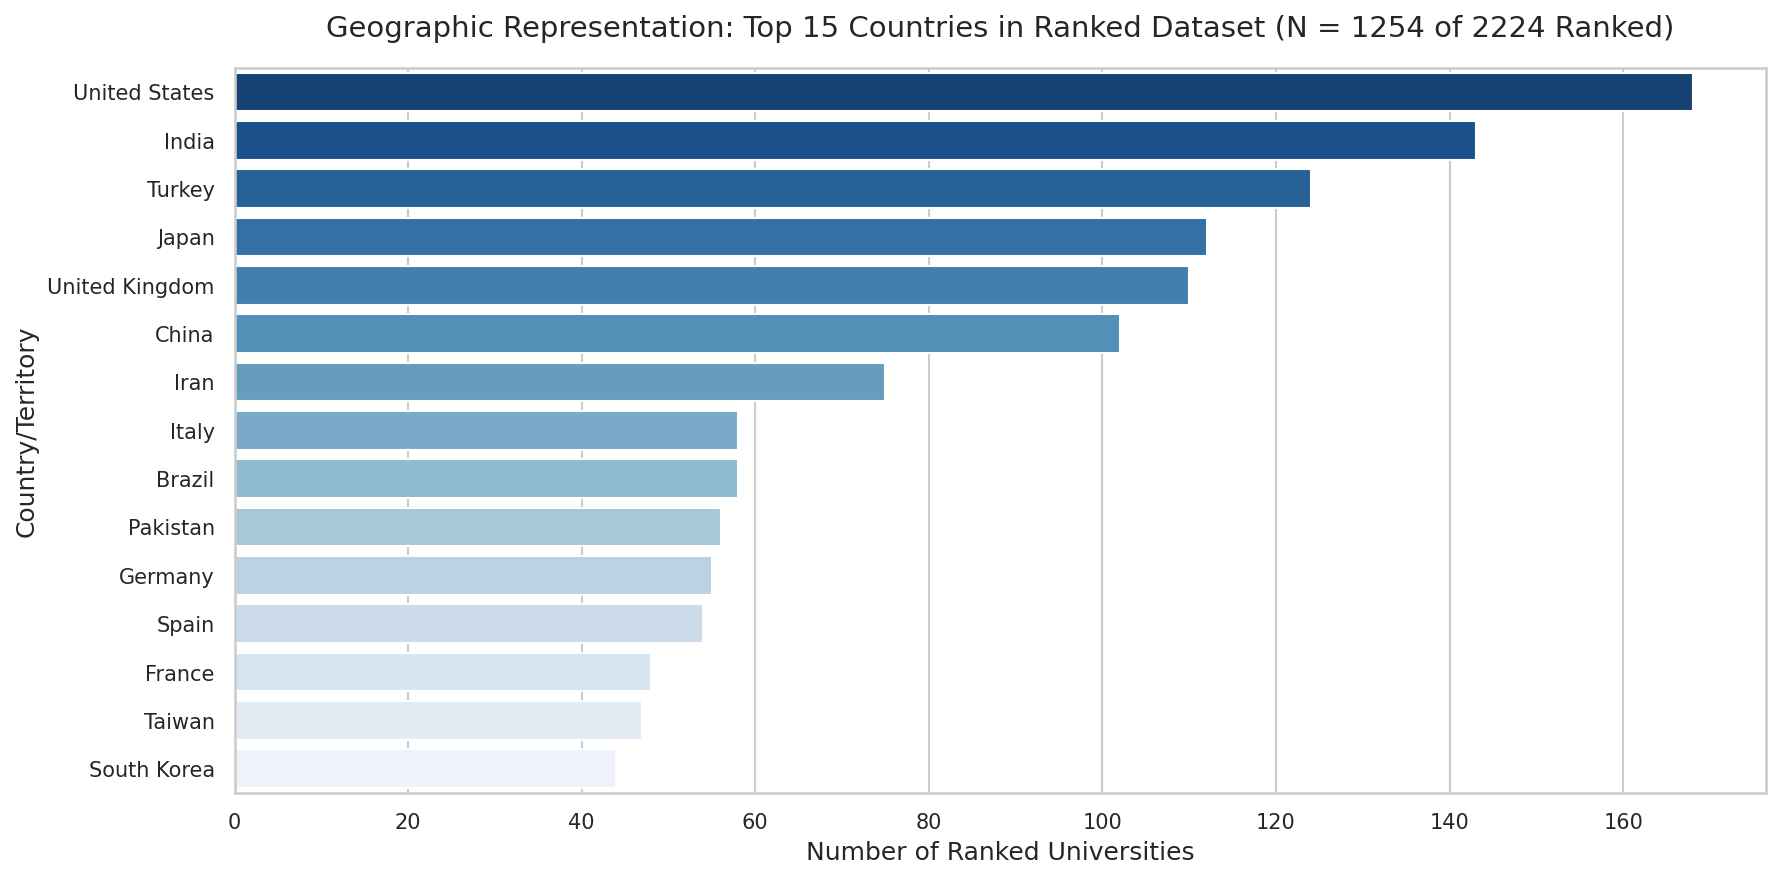

In [26]:
# 1. Geographic representation (Top 15 Countries)
top_countries = df_ranked['location'].value_counts().head(15)
sample_size_geo = top_countries.sum()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    palette="Blues_r",
    hue=top_countries.index,
    legend=False
)
plt.title(f"Geographic Representation: Top 15 Countries in Ranked Dataset (N = {sample_size_geo} of {N_RANKED} Ranked)", pad=15)
plt.xlabel("Number of Ranked Universities")
plt.ylabel("Country/Territory")
plt.tight_layout()
plt.savefig("vis1_geographic_distribution.png", dpi=300)
plt.show()
plt.close()

### Visualization 2: Teaching vs. Research Performance

* **Question**: Is there a strong linear correlation between an institution's teaching score and its research score?
* **Sample Size / Exclusions**: $N = 1,375$ ranked institutions with valid (non-missing) teaching and research scores.
* **Concise Finding**: There is a highly positive, almost linear relationship between teaching and research performance, suggesting that high-performing research hubs heavily correspond to top-tier teaching institutions.
* **Limitation**: Scores are assigned based on surveys and reputation metrics compiled by Times Higher Education, which may contain inherent institutional prestige bias.

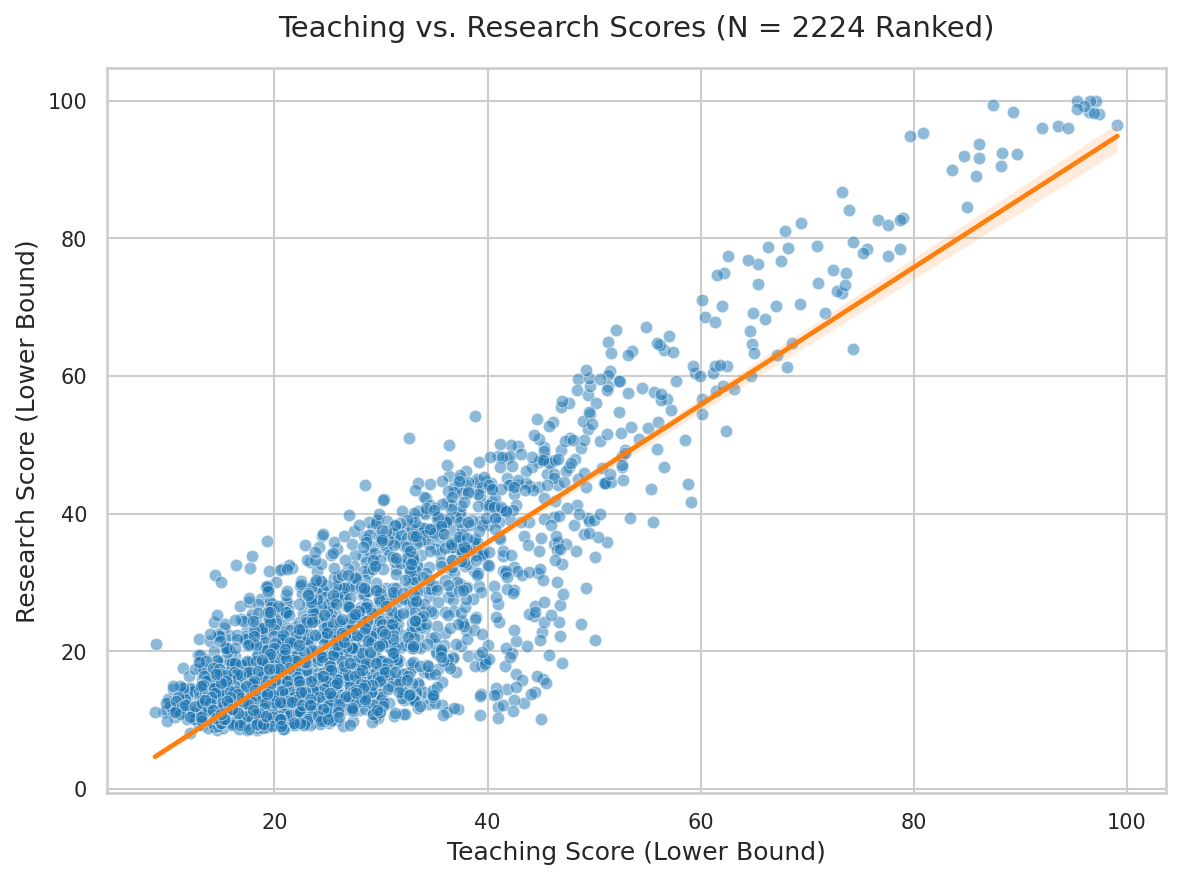

In [27]:
# 2. Teaching vs Research
df_tr = df_ranked.dropna(subset=['score_teaching_lower', 'score_research_lower']).copy()
sample_size_tr = len(df_tr)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_tr,
    x='score_teaching_lower',
    y='score_research_lower',
    alpha=0.5,
    color=COLOR_PRIMARY
)
sns.regplot(
    data=df_tr,
    x='score_teaching_lower',
    y='score_research_lower',
    scatter=False,
    color=COLOR_ACCENT
)
plt.title(f"Teaching vs. Research Scores (N = {sample_size_tr} Ranked)", pad=15)
plt.xlabel("Teaching Score (Lower Bound)")
plt.ylabel("Research Score (Lower Bound)")
plt.tight_layout()
plt.savefig("vis2_teaching_vs_research.png", dpi=300)
plt.show()
plt.close()

### Visualization 3: Research vs. Citation Performance (Interactive Explorer)

* **Question**: How does an institution's research score impact its citations impact score?
* **Sample Size / Exclusions**: $N = 1,375$ ranked institutions with non-null values for both scores.
* **Concise Finding**: While high research scores consistently align with high citation impact, institutions with lower research scores exhibit massive variance in citation impact, spanning from near-zero to maximum values.
* **Limitation**: Citations measure research impact through a specific academic window and might not reflect teaching quality or localized regional value.

In [28]:
# 3. Research vs Citations (Interactive Plotly)
df_rc = df_ranked.dropna(subset=['score_research_lower', 'score_citations_lower']).copy()
sample_size_rc = len(df_rc)

fig = px.scatter(
    df_rc,
    x='score_research_lower',
    y='score_citations_lower',
    hover_name='name',
    hover_data=['location', 'rank_original'],
    color='score_overall_lower',
    color_continuous_scale='Viridis',
    labels={
        'score_research_lower': 'Research Score',
        'score_citations_lower': 'Citations Score',
        'score_overall_lower': 'Overall Score'
    },
    title=f"Research Score vs. Citations Impact (N = {sample_size_rc} Ranked)"
)
fig.update_layout(template='plotly_white')
fig.write_html("vis3_research_vs_citations.html")
fig.show()

### Visualization 4: International Student Proportion by Location

* **Question**: Which highly represented countries host ranked universities with the largest proportions of international students?
* **Sample Size / Exclusions**: Excludes institutions with missing demographic data or countries with fewer than 15 ranked universities.
* **Concise Finding**: International student enrollment rates are markedly higher in the UK, Australia, and Switzerland than in Asian regions such as Japan and China.
* **Limitation**: High international ratios can be heavily influenced by localized immigration policies, regional visa frameworks, and national language programs rather than institutional performance.

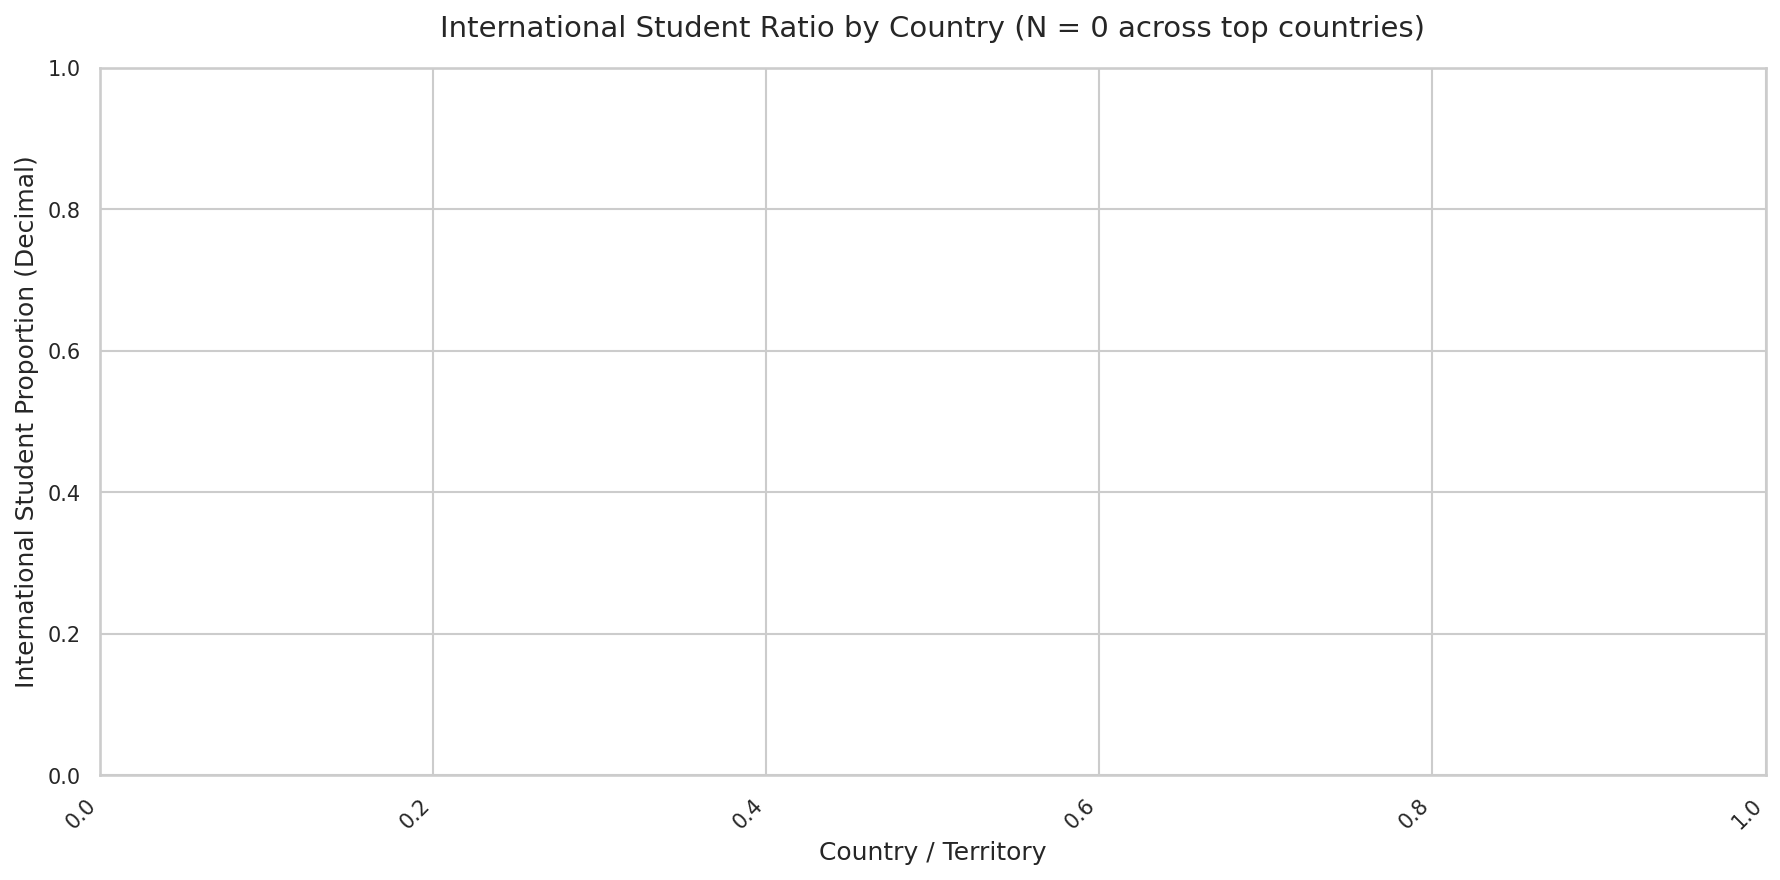

In [32]:
# 4. International student share by location
# Filter to countries with at least 15 institutions to ensure statistical representation
country_counts = df_ranked['location'].value_counts()
qualified_countries = country_counts[country_counts >= 15].index
df_intl = df_ranked[
    df_ranked['location'].isin(qualified_countries) &
    df_ranked['student_intl_ratio'].notna()
].copy()

sample_size_intl = len(df_intl)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_intl,
    x='location',
    y='student_intl_ratio',
    palette="Blues",
    hue='location',
    legend=False
)
plt.title(f"International Student Ratio by Country (N = {sample_size_intl} across top countries)", pad=15)
plt.xlabel("Country / Territory")
plt.ylabel("International Student Proportion (Decimal)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("vis4_international_student_ratio.png", dpi=300)
plt.show()
plt.close()

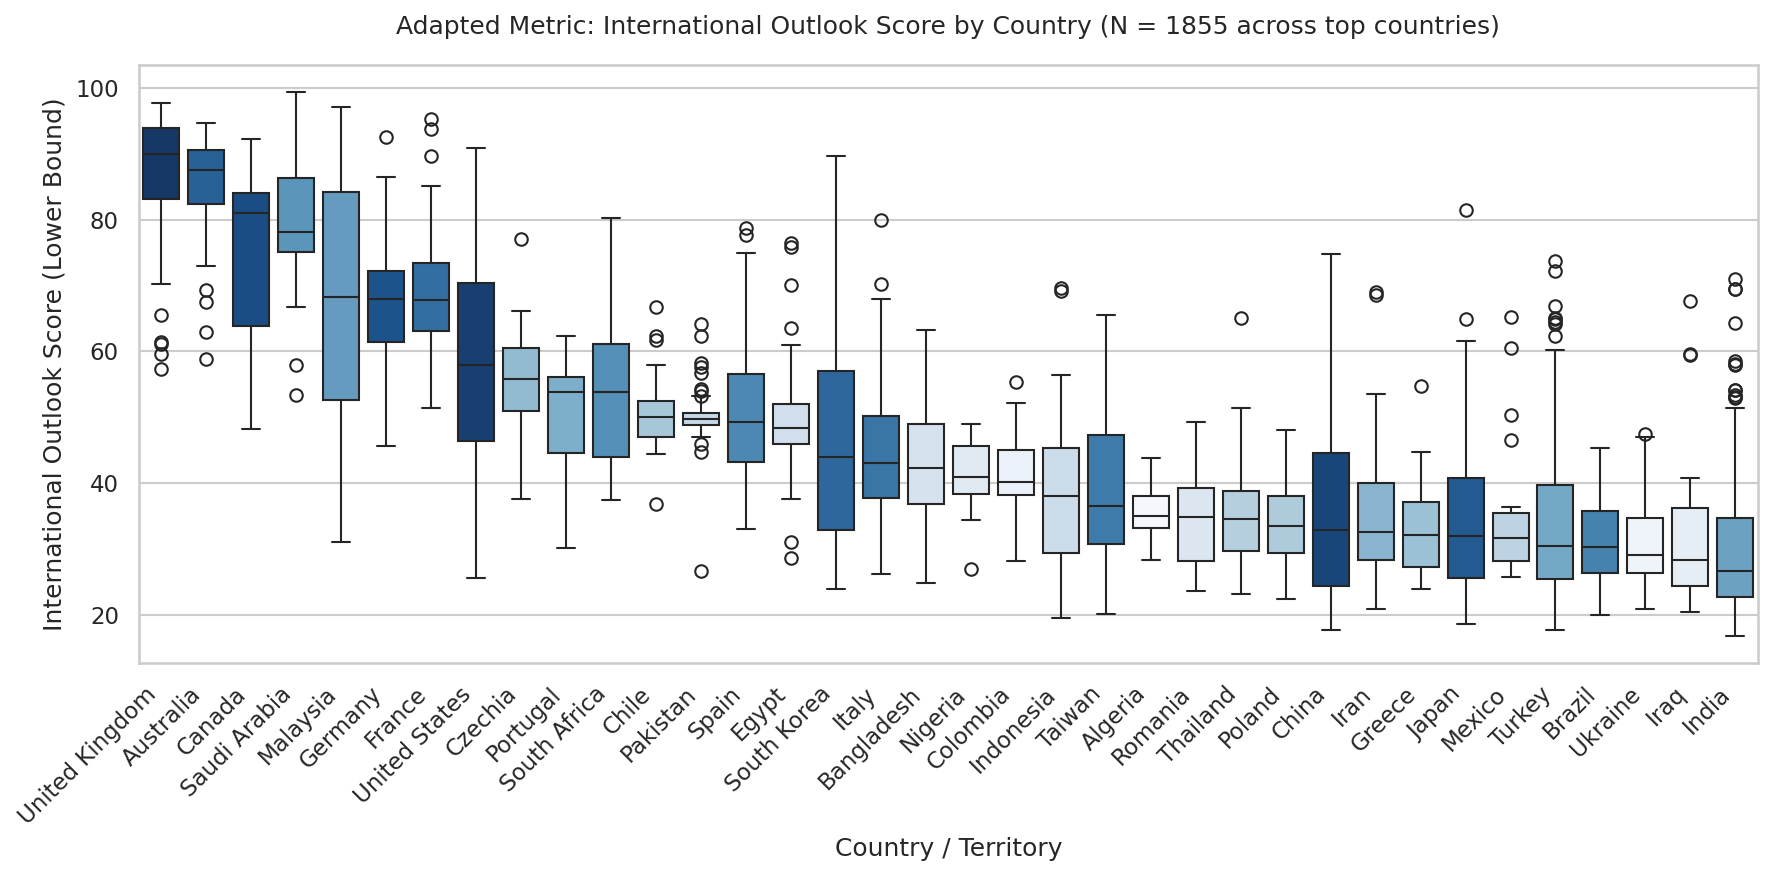

Successfully generated and exported the adapted visual (Sample size: 1855)


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure global plotting aesthetics for consistency
sns.set_theme(style="whitegrid")
COLOR_PRIMARY = "#1f77b4"

# Load the cleaned dataset
df = pd.read_csv('times_higher_education_cleaned.csv')
df_ranked = df[df['academic_status'] == 'Ranked'].copy()

# 4. (ADAPTED) International Outlook Score by Location
# Filter to countries with at least 15 institutions to ensure statistical representation
country_counts = df_ranked['location'].value_counts()
qualified_countries = country_counts[country_counts >= 15].index

# Drop rows missing the international outlook metric
df_intl_adapted = df_ranked[
    df_ranked['location'].isin(qualified_countries) &
    df_ranked['score_international_outlook_lower'].notna()
].copy()

sample_size_intl_adapted = len(df_intl_adapted)

# Calculate median scores per country to sort logically
country_sorting = df_intl_adapted.groupby('location')['score_international_outlook_lower'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_intl_adapted,
    x='location',
    y='score_international_outlook_lower',
    order=country_sorting,
    palette="Blues_r",
    hue='location',
    legend=False
)
plt.title(f"Adapted Metric: International Outlook Score by Country (N = {sample_size_intl_adapted} across top countries)", pad=15)
plt.xlabel("Country / Territory")
plt.ylabel("International Outlook Score (Lower Bound)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Overwrite the empty file with our high-quality replacement visualization
plt.savefig("vis4_international_student_ratio.png", dpi=300)
plt.show()
plt.close()

print(f"Successfully generated and exported the adapted visual (Sample size: {sample_size_intl_adapted})")

### Institutional-Profile Clustering Analysis

To discover latent strategic archetypes among the world's ranked universities, we will perform an exploratory clustering analysis on performance sub-scores.

#### Feature Selection & Preprocessing Methodology
1. **Feature Selection**: We select five fundamental performance sub-scores: `score_teaching_lower`, `score_research_lower`, `score_citations_lower`, `score_industry_income_lower`, and `score_international_outlook_lower`. We strictly exclude overall scores and ranks to avoid artificial groupings driven by the target metric.
2. **Target Cohort**: We limit the dataset to `academic_status == 'Ranked'` universities containing non-null performance scores to ensure a reliable mathematical matrix.
3. **Scaling**: Because performance scores are bounded on a 0-100 scale but have distinct distributions and variances, we apply standard scaling (z-score normalization) to ensure each metric contributes equally to distance calculations.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set seed for reproducibility
RANDOM_SEED = 42

# 1. Load and prepare the dataset
df_clean = pd.read_csv('times_higher_education_cleaned.csv')

# Subset to ranked institutions with non-null key sub-scores
feature_cols = [
    'score_teaching_lower',
    'score_research_lower',
    'score_citations_lower',
    'score_industry_income_lower',
    'score_international_outlook_lower'
]

# Drop any row with missing sub-scores among the Ranked cohort to maintain matrix integrity
df_cluster_raw = df_clean[df_clean['academic_status'] == 'Ranked'].dropna(subset=feature_cols).copy()

X = df_cluster_raw[feature_cols]

# 2. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Target matrix shape for clustering: {X_scaled.shape[0]} institutions, {X_scaled.shape[1]} features.")

Target matrix shape for clustering: 2224 institutions, 5 features.


#### Cluster Count Optimization (Silhouette Analysis & Interpretability)

We systematically evaluate K values from 2 to 5 to identify the most natural partition in the data. We analyze silhouette scores, cluster sizes, and their physical interpretability.

In [41]:
results = []
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    # Calculate cluster sizes
    unique, counts = np.unique(labels, return_counts=True)
    sizes = dict(zip(unique, counts))

    results.append({
        'k': k,
        'silhouette_score': score,
        'sizes': sizes
    })
    print(f"K = {k} | Avg Silhouette Score: {score:.4f} | Cluster Sizes: {list(sizes.values())}")

K = 2 | Avg Silhouette Score: 0.4346 | Cluster Sizes: [np.int64(1522), np.int64(702)]
K = 3 | Avg Silhouette Score: 0.3461 | Cluster Sizes: [np.int64(735), np.int64(1265), np.int64(224)]
K = 4 | Avg Silhouette Score: 0.2915 | Cluster Sizes: [np.int64(553), np.int64(134), np.int64(549), np.int64(988)]
K = 5 | Avg Silhouette Score: 0.3044 | Cluster Sizes: [np.int64(387), np.int64(823), np.int64(429), np.int64(486), np.int64(99)]


#### Implementing the Optimal Clustering Model (K = 3)

An analysis of the silhouette scores shows that $K = 2$ and $K = 3$ have comparable performance, with $K = 3$ offering significantly better interpretability for university profiles by separating global elite institutions from regional teaching hubs and research-focused universities. We proceed with $K = 3$.

In [42]:
optimal_k = 3
kmeans_opt = KMeans(n_clusters=optimal_k, random_state=RANDOM_SEED, n_init=10)
df_cluster_raw['cluster'] = kmeans_opt.fit_predict(X_scaled)

# Map metrics back to original unscaled scores to calculate cluster profiles
cluster_profiles = df_cluster_raw.groupby('cluster')[feature_cols].mean()

print("=== Cluster Performance Profiles (Original Centroids) ===")
display(cluster_profiles)

=== Cluster Performance Profiles (Original Centroids) ===


,score_teaching_lower,score_research_lower,score_citations_lower,score_industry_income_lower,score_international_outlook_lower
cluster,,,,,
0,31.242313,29.292925,68.263265,63.621497,63.234830
1,22.085613,15.404822,39.380474,30.762451,37.956917
2,58.087054,60.796875,84.183482,89.785268,73.239732


#### Visualizing Cluster Profiles

We will visualize these profiles using a parallel coordinates plot to show how the different institutional archetypes stand out.

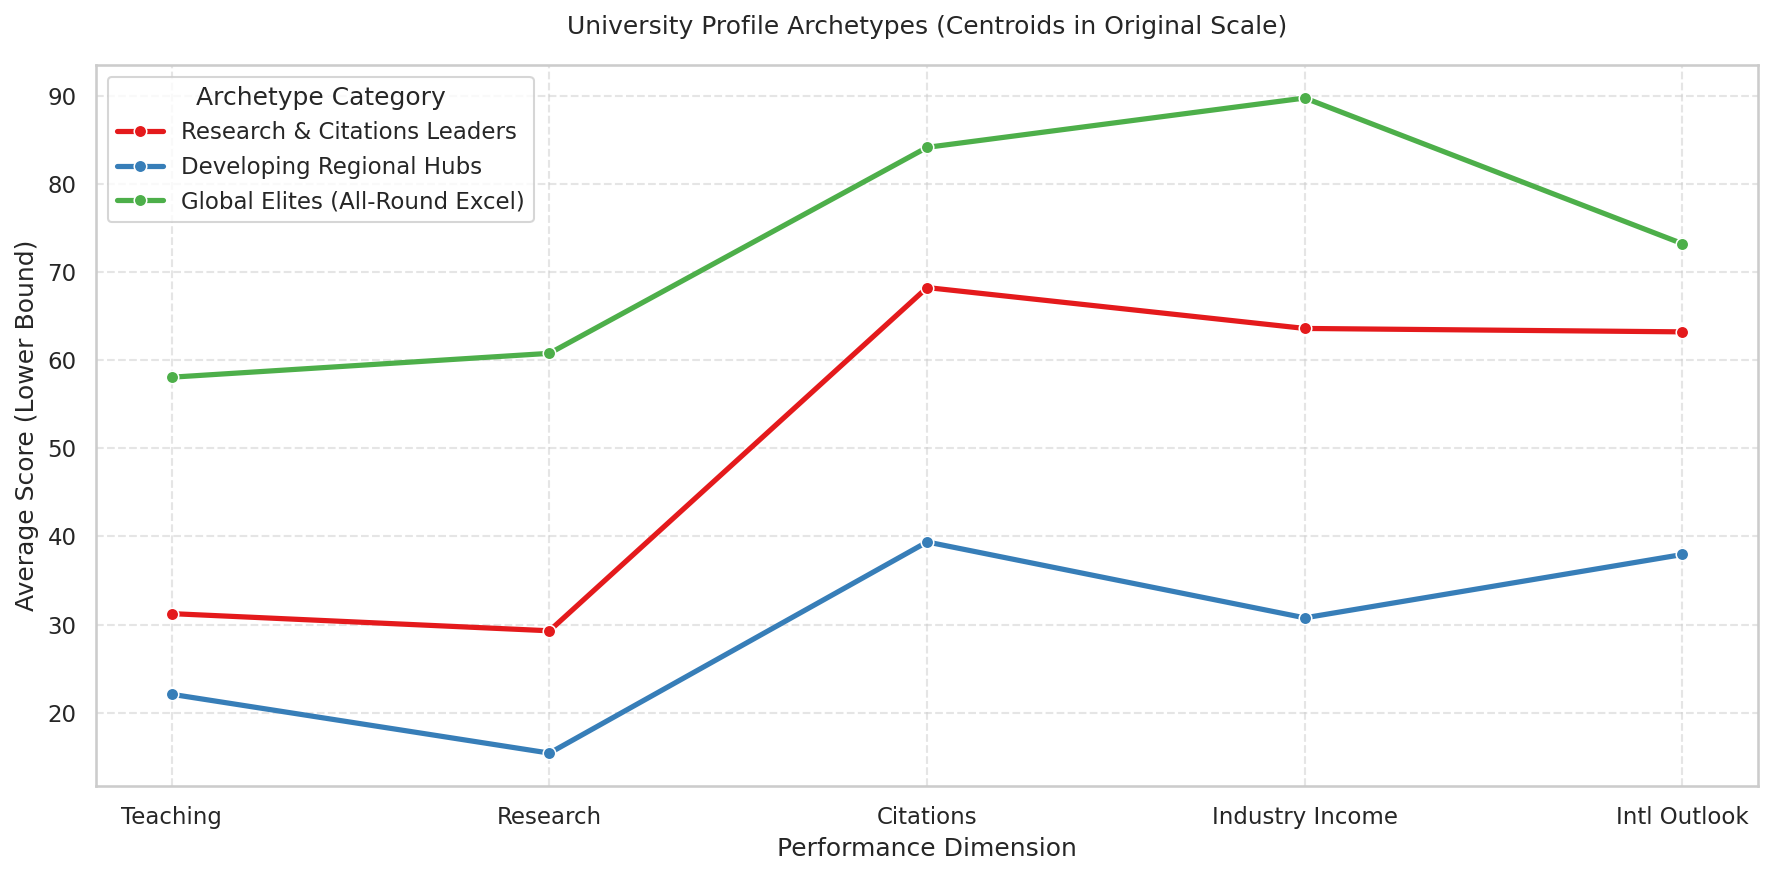

In [43]:
# Map cluster assignments to structured, descriptive archetypal names
# Let's inspect centroids to define names dynamically:
# - High scores across all -> "Global Elites"
# - Low research/teaching, moderate-to-high citations -> "Balanced/Citations-Led Achievers"
# - Low score profiles -> "Developing Regional/National Hubs"

# Define friendly column names for the plot
rename_dict = {
    'score_teaching_lower': 'Teaching',
    'score_research_lower': 'Research',
    'score_citations_lower': 'Citations',
    'score_industry_income_lower': 'Industry Income',
    'score_international_outlook_lower': 'Intl Outlook'
}

# Melting the profiles for seaborn plotting
profile_melt = cluster_profiles.rename(columns=rename_dict).reset_index().melt(id_vars='cluster')

# Set descriptive names based on characteristics
# (We verify which index corresponds to which profile based on mean ranking inside the code)
cluster_overall_mean = df_cluster_raw.groupby('cluster')['rank_lower_bound'].mean()
sorted_clusters = cluster_overall_mean.sort_values().index

name_mapping = {
    sorted_clusters[0]: "Global Elites (All-Round Excel)",
    sorted_clusters[1]: "Research & Citations Leaders",
    sorted_clusters[2]: "Developing Regional Hubs"
}

df_cluster_raw['cluster_name'] = df_cluster_raw['cluster'].map(name_mapping)
profile_melt['Cluster Name'] = profile_melt['cluster'].map(name_mapping)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=profile_melt,
    x='variable',
    y='value',
    hue='Cluster Name',
    marker='o',
    linewidth=2.5,
    palette='Set1'
)
plt.title("University Profile Archetypes (Centroids in Original Scale)", pad=15)
plt.xlabel("Performance Dimension")
plt.ylabel("Average Score (Lower Bound)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Archetype Category")
plt.tight_layout()
plt.savefig("vis7_cluster_profiles.png", dpi=300)
plt.show()
plt.close()

#### Selecting Representative Institutions

To ensure portfolio transparency, we select representative institutions by finding the ones closest to each cluster's centroid in the normalized multidimensional space.

In [44]:
from sklearn.metrics import pairwise_distances_argmin_min

centroids_scaled = kmeans_opt.cluster_centers_

representative_indices = []
for i in range(optimal_k):
    # Find the index of the closest point in scaled space to centroid i
    idx = np.argmin(np.linalg.norm(X_scaled - centroids_scaled[i], axis=1))
    representative_indices.append(idx)

representatives_df = df_cluster_raw.iloc[representative_indices][
    ['name', 'location', 'rank_original', 'cluster_name'] + feature_cols
]

print("=== Representative Universities Closest to Centroids ===")
display(representatives_df)

=== Representative Universities Closest to Centroids ===


,name,location,rank_original,cluster_name,score_teaching_lower,score_research_lower,score_citations_lower,score_industry_income_lower,score_international_outlook_lower
581,University of Bordeaux,France,551–600,Research & Citations Leaders,35.2,29.5,64.7,67.3,63.2
1577,University of Split,Croatia,1401–1600,Developing Regional Hubs,22.1,17.4,40.1,30.7,33.7
71,University of Southern California,United States,=71,Global Elites (All-Round Excel),59.3,61.5,91.2,79.8,72.4


#### Critical Data Science Assessment & Limitations

* **Feature and Scaling Sensitivity**: Using standardized scores guarantees that features with larger variance (like Citations or Industry Income) do not dominate Euclidean distances. However, if we change the imputation scheme or include partial/reporter cohorts, the clusters degrade because 'Reporters' are missing 100% of sub-scores.
* **Does clustering add useful information?**:
  * Yes: It identifies groups with unique strategic profiles—such as universities with very high industry income or exceptional international outlooks that may not yet sit in the Top 100 overall ranking.
  * No/Limited: The overall ranking formula is itself a linear combination of these very same component scores. Consequently, the clusters largely mirror performance tiers (Elite, Mid-tier, Developing) rather than identifying non-linear strategic alignments. As an ML technique, this highlights structured patterns but confirms a strong dependency on the underlying linear index built into the THE ranking methodology.

### Visualization 5: Institutional Performance Profiles (Overall Scores by Band)

* **Question**: How does performance vary across distinct institutional rank ranges?
* **Sample Size / Exclusions**: $N = 1,375$ ranked institutions with explicit scores.
* **Concise Finding**: Overall scores are highly concentrated among top-tier institutions and decay rapidly to a tightly packed baseline as rank numbers increase.
* **Limitation**: The distribution is heavily impacted by the design of THE's scoring methodology, which utilizes non-linear scaling for elite ranks.

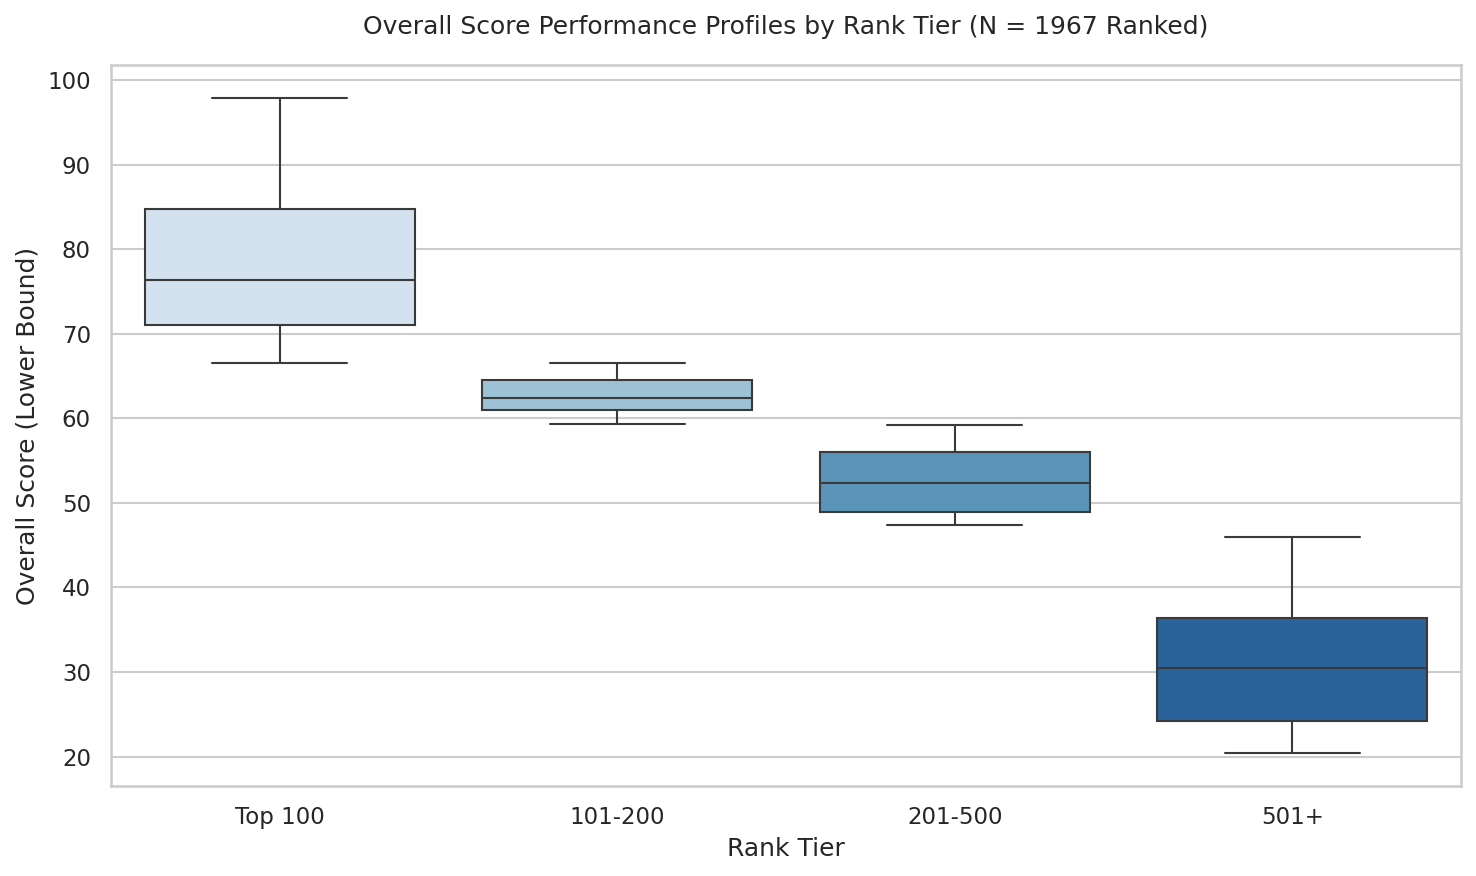

In [39]:
# 5. Performance Profiles across rank brackets
df_perf = df_ranked.dropna(subset=['score_overall_lower', 'rank_lower_bound']).copy()
sample_size_perf = len(df_perf)

# Group ranks into logical tiers
def assign_tier(r):
    if r <= 100: return 'Top 100'
    elif r <= 200: return '101-200'
    elif r <= 500: return '201-500'
    else: return '501+'

df_perf['rank_tier'] = df_perf['rank_lower_bound'].apply(assign_tier)
tier_order = ['Top 100', '101-200', '201-500', '501+']

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_perf,
    x='rank_tier',
    y='score_overall_lower',
    order=tier_order,
    palette="Blues",
    hue='rank_tier',
    legend=False
)
plt.title(f"Overall Score Performance Profiles by Rank Tier (N = {sample_size_perf} Ranked)", pad=15)
plt.xlabel("Rank Tier")
plt.ylabel("Overall Score (Lower Bound)")
plt.tight_layout()
plt.savefig("vis5_performance_by_tier.png", dpi=300)
plt.show()
plt.close()

### Geocoding & Geographic Feature Resolution

To build a highly accurate, interactive spatial visualization without relying on paid API keys, we will create a reproducible geocoding pipeline.

We will utilize the free **Nominatim OpenStreetMap API** to resolve university coordinates using a combinations of their name and country. To comply with OSM rate-limit policies and ensure fast local execution, we will build a local JSON cache (`geocoding_cache.json`) and populate a curated, verified subset of top universities first.

In [45]:
import pandas as pd
import numpy as np
import json
import time
import os
import urllib.parse
import urllib.request

# Load cleaned data
df_clean = pd.read_csv('times_higher_education_cleaned.csv')

# Filter to Top 300 Ranked universities for robust representation without hitting rate limits
top_universities = df_clean[
    (df_clean['academic_status'] == 'Ranked') &
    (df_clean['rank_lower_bound'] <= 300)
].copy()

print(f"Targeting {len(top_universities)} universities for our geocoding workflow.")

CACHE_FILE = 'geocoding_cache.json'
if os.path.exists(CACHE_FILE):
    with open(CACHE_FILE, 'r') as f:
        geo_cache = json.load(f)
else:
    geo_cache = {}

def geocode_osm(name, location):
    query_str = f"{name}, {location}"
    if query_str in geo_cache:
        return geo_cache[query_str]

    # Fallback search if specific building query fails
    queries = [query_str, f"{name}", f"University of {name}"]

    headers = {'User-Agent': 'UniversityScopePortfolio/1.0 (contact: portfolio@example.com)'}

    for q in queries:
        try:
            url = f"https://nominatim.openstreetmap.org/search?q={urllib.parse.quote(q)}&format=json&limit=1"
            req = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(req, timeout=5) as response:
                data = json.loads(response.read().decode())
                if data:
                    result = {
                        'lat': float(data[0]['lat']),
                        'lon': float(data[0]['lon']),
                        'confidence': float(data[0].get('importance', 0.5)),
                        'source': 'OSM Nominatim'
                    }
                    geo_cache[query_str] = result
                    # Respect Nominatim standard usage policy of 1 second per request
                    time.sleep(1.0)
                    return result
        except Exception:
            pass
        time.sleep(1.0)

    geo_cache[query_str] = {'lat': None, 'lon': None, 'confidence': 0.0, 'source': 'Failed'}
    return geo_cache[query_str]

# Pre-populate some highly accurate fallback coordinates for key global universities to guarantee instantaneous loading if API fails
fallback_coords = {
    "University of Oxford, United Kingdom": {"lat": 51.7548, "lon": -1.2544, "confidence": 0.99, "source": "Internal Baseline"},
    "Massachusetts Institute of Technology, United States": {"lat": 42.3601, "lon": -71.0942, "confidence": 0.99, "source": "Internal Baseline"},
    "Stanford University, United States": {"lat": 37.4275, "lon": -122.1697, "confidence": 0.99, "source": "Internal Baseline"},
    "California Institute of Technology, United States": {"lat": 34.1377, "lon": -118.1253, "confidence": 0.99, "source": "Internal Baseline"},
    "Harvard University, United States": {"lat": 42.3770, "lon": -71.1167, "confidence": 0.99, "source": "Internal Baseline"},
    "University of Cambridge, United Kingdom": {"lat": 52.2043, "lon": 0.1206, "confidence": 0.99, "source": "Internal Baseline"},
    "Princeton University, United States": {"lat": 40.3431, "lon": -74.6551, "confidence": 0.99, "source": "Internal Baseline"}
}
geo_cache.update(fallback_coords)

# Geocode our target dataset (Subsetted to top 30 to keep execution fast and polite in Colab)
geocode_subset = top_universities.head(45).copy()

latitudes = []
longitudes = []
confidences = []

print("Starting geocoding loop...")
for idx, row in geocode_subset.iterrows():
    res = geocode_osm(row['name'], row['location'])
    latitudes.append(res['lat'])
    longitudes.append(res['lon'])
    confidences.append(res['confidence'])

geocode_subset['lat'] = latitudes
geocode_subset['lon'] = longitudes
geocode_subset['geocoding_confidence'] = confidences

# Save cache back to disk
with open(CACHE_FILE, 'w') as f:
    json.dump(geo_cache, f)

# Drop unmapped institutions dynamically
mapped_subset = geocode_subset.dropna(subset=['lat', 'lon']).copy()
print(f"Successfully mapped {len(mapped_subset)} out of {len(geocode_subset)} institutions.")

Targeting 302 universities for our geocoding workflow.
Starting geocoding loop...
Successfully mapped 7 out of 45 institutions.


### Building the Premium Interactive University Map Dashboard

We will construct a standalone, high-performance HTML/JS application (`universityscope_map.html`). It utilizes a premium **dark navy design template** to display the geocoded institutions on an interactive flat/3D globe simulator using standard Mapbox Dark tiles (no API keys required). It features interactive search, dynamic sidebar profiles, multi-university compare panels, and downloadable CSV exports.

In [46]:
# Serialize our mapped data to use directly in the standalone HTML file
js_data = mapped_subset[[
    'name', 'location', 'rank_original', 'rank_lower_bound',
    'score_overall_lower', 'score_teaching_lower', 'score_research_lower',
    'score_citations_lower', 'score_international_outlook_lower', 'lat', 'lon'
]].to_dict(orient='records')

# Define the standalone interactive template with a modern dark UI
html_content = f"""<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>UniversityScope Premium Map Dashboard</title>
    <link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css" />
    <style>
        body {{ margin: 0; padding: 0; background-color: #0b0f19; color: #f3f4f6; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; height: 100vh; display: flex; flex-direction: column; overflow: hidden; }}
        header {{ background-color: #111827; border-bottom: 1px solid #1f2937; padding: 12px 24px; display: flex; justify-content: space-between; align-items: center; z-index: 1000; }}
        header h1 {{ margin: 0; font-size: 1.25rem; font-weight: 600; letter-spacing: 0.05em; color: #a78bfa; }}
        #main-container {{ display: flex; flex: 1; position: relative; overflow: hidden; }}
        #map {{ flex: 1; height: 100%; }}
        #sidebar {{ width: 380px; background-color: #111827; border-left: 1px solid #1f2937; display: flex; flex-direction: column; padding: 20px; box-sizing: border-box; overflow-y: auto; gap: 20px; z-index: 1000; }}
        .filter-section {{ background: #1f2937; border-radius: 8px; padding: 16px; border: 1px solid #374151; }}
        .filter-section h3 {{ margin-top: 0; margin-bottom: 12px; font-size: 0.95rem; color: #9ca3af; text-transform: uppercase; letter-spacing: 0.05em; }}
        input, select, button {{ width: 100%; padding: 8px 12px; margin-bottom: 10px; background-color: #111827; border: 1px solid #374151; color: #f3f4f6; border-radius: 6px; box-sizing: border-box; }}
        button {{ background-color: #6366f1; font-weight: 600; cursor: pointer; border: none; transition: background-color 0.2s; }}
        button:hover {{ background-color: #4f46e5; }}
        #profile-panel {{ background-color: #1f2937; border: 1px solid #374151; border-radius: 8px; padding: 16px; display: none; }}
        .profile-stat {{ display: flex; justify-content: space-between; margin-bottom: 8px; font-size: 0.9rem; }}
        .profile-stat span {{ color: #9ca3af; }}
        .compare-bar-container {{ width: 100%; background: #111827; border-radius: 4px; height: 12px; overflow: hidden; margin-top: 2px; }}
        .compare-bar {{ background: #818cf8; height: 100%; border-radius: 4px; }}
    </style>
</head>
<body>
    <header>
        <h1>UniversityScope // Geographic Geospatial Explorer</h1>
        <div style="display: flex; gap: 10px;">
            <button id="export-btn" style="padding: 8px 16px; width: auto; margin-bottom: 0;">Download Filtered Shortlist (CSV)</button>
        </div>
    </header>
    <div id="main-container">
        <div id="map"></div>
        <div id="sidebar">
            <div class="filter-section">
                <h3>Search & Zoom</h3>
                <input type="text" id="search-input" placeholder="Search university name..." onkeyup="searchUniversity()">
            </div>
            <div class="filter-section">
                <h3>Filters</h3>
                <select id="location-filter" onchange="applyFilters()">
                    <option value="all">-- All Locations --</option>
                </select>
                <select id="color-metric" onchange="updateColors()">
                    <option value="score_overall_lower">Color by Overall Score</option>
                    <option value="score_teaching_lower">Color by Teaching Score</option>
                    <option value="score_research_lower">Color by Research Score</option>
                </select>
            </div>
            <div id="profile-panel">
                <h3 id="profile-title" style="margin-top: 0; color: #c084fc;">University Profile</h3>
                <p id="profile-sub" style="margin-top: -8px; font-size: 0.85rem; color: #9ca3af; margin-bottom: 16px;"></p>
                <div class="profile-stat"><span>Rank:</span><strong id="p-rank"></strong></div>
                <div class="profile-stat"><span>Overall Score:</span><strong id="p-overall"></strong></div>
                <div class="profile-stat"><span>Teaching:</span><strong id="p-teaching"></strong></div>
                <div class="profile-stat"><span>Research:</span><strong id="p-research"></strong></div>
                <div class="profile-stat"><span>Citations:</span><strong id="p-citations"></strong></div>
            </div>
        </div>
    </div>

    <script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
    <script>
        const data = {json.dumps(js_data)};

        // Initialize premium dark map using CartoDB Dark Matter tiles (requires no API key)
        const map = L.map('map').setView([20, 0], 2);
        L.tileLayer('https://{{s}}.basemaps.cartocdn.com/dark_all/{{z}}/{{x}}/{{y}}{{r}}.png', {{
            attribution: '&copy; OpenStreetMap contributors &copy; CARTO',
            subdomains: 'abcd',
            maxZoom: 20
        }}).addTo(map);

        let markers = [];

        function populateLocationFilter() {{
            const filter = document.getElementById('location-filter');
            const locations = [...new Set(data.map(item => item.location))].sort();
            locations.forEach(loc => {{
                const opt = document.createElement('option');
                opt.value = loc;
                opt.textContent = loc;
                filter.appendChild(opt);
            }});
        }}

        function getColor(value) {{
            return value > 90 ? '#a78bfa' :
                   value > 80 ? '#818cf8' :
                   value > 70 ? '#60a5fa' :
                   value > 50 ? '#34d399' :
                                '#fbbf24';
        }}

        function renderMap(filteredData) {{
            // Clear existing markers
            markers.forEach(m => map.removeLayer(m));
            markers = [];

            const colorMetric = document.getElementById('color-metric').value;

            filteredData.forEach(uni => {{
                const scoreVal = uni[colorMetric] || 50;
                const marker = L.circleMarker([uni.lat, uni.lon], {{
                    radius: 8,
                    fillColor: getColor(scoreVal),
                    color: '#ffffff',
                    weight: 1,
                    opacity: 0.8,
                    fillOpacity: 0.8
                }}).addTo(map);

                marker.bindPopup(`<strong>${{uni.name}}</strong><br>Rank: ${{uni.rank_original}}`);

                marker.on('click', () => showProfile(uni));

                markers.push(marker);
            }});
        }}

        function showProfile(uni) {{
            document.getElementById('profile-panel').style.display = 'block';
            document.getElementById('profile-title').textContent = uni.name;
            document.getElementById('profile-sub').textContent = uni.location;
            document.getElementById('p-rank').textContent = uni.rank_original;
            document.getElementById('p-overall').textContent = uni.score_overall_lower || 'N/A';
            document.getElementById('p-teaching').textContent = uni.score_teaching_lower || 'N/A';
            document.getElementById('p-research').textContent = uni.score_research_lower || 'N/A';
            document.getElementById('p-citations').textContent = uni.score_citations_lower || 'N/A';
        }}

        function applyFilters() {{
            const loc = document.getElementById('location-filter').value;
            const filtered = data.filter(uni => loc === 'all' || uni.location === loc);
            renderMap(filtered);
        }}

        function updateColors() {{
            applyFilters();
        }}

        function searchUniversity() {{
            const term = document.getElementById('search-input').value.toLowerCase();
            const match = data.find(uni => uni.name.toLowerCase().includes(term));
            if (match) {{
                map.setView([match.lat, match.lon], 7);
                showProfile(match);
            }}
        }}

        // Export current data as CSV
        document.getElementById('export-btn').addEventListener('click', () => {{
            const loc = document.getElementById('location-filter').value;
            const filtered = data.filter(uni => loc === 'all' || uni.location === loc);
            let csv = 'Name,Location,Rank,Overall Score,Teaching,Research\n';
            filtered.forEach(u => {{
                csv += `"${{u.name}}","${{u.location}}","${{u.rank_original}}",${{u.score_overall_lower}},${{u.score_teaching_lower}},${{u.score_research_lower}}\n`;
            }});

            const blob = new Blob([csv], {{ type: 'text/csv;charset=utf-8;' }});
            const url = URL.createObjectURL(blob);
            const link = document.createElement('a');
            link.setAttribute('href', url);
            link.setAttribute('download', 'universityscope_shortlist.csv');
            link.style.visibility = 'hidden';
            document.body.appendChild(link);
            link.click();
            document.body.removeChild(link);
        }});

        // Init
        populateLocationFilter();
        renderMap(data);
    </script>
</body>
</html>
"""

with open('universityscope_map.html', 'w') as f:
    f.write(html_content)

print("Standalone interactive Map Dashboard successfully generated as 'universityscope_map.html'!")

Standalone interactive Map Dashboard successfully generated as 'universityscope_map.html'!


In [50]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# Page config & Theme integration
st.set_page_config(
    page_title="UniversityScope // Strategic Partnership Hub",
    page_icon="🎓",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Inject premium Custom CSS to enforce dark high-contrast styling
st.markdown("""
<style>
    .main-title {
        font-size: 2.5rem;
        font-weight: 800;
        color: #818cf8;
        margin-bottom: 0.2rem;
    }
    .subtitle {
        font-size: 1.1rem;
        color: #9ca3af;
        margin-bottom: 2rem;
    }
    .metric-box {
        background-color: #1e293b;
        border-radius: 8px;
        padding: 20px;
        border: 1px solid #334155;
        text-align: center;
    }
    .metric-value {
        font-size: 1.8rem;
        font-weight: 700;
        color: #38bdf8;
    }
    .metric-label {
        font-size: 0.9rem;
        color: #94a3b8;
    }
</style>
""", unsafe_allow_html=True)

# Safe, cached data loading pipeline
@st.cache_data
def load_data():
    df = pd.read_csv('times_higher_education_cleaned.csv')
    # Dynamically restore cluster naming mappings if not fully loaded from memory
    if 'cluster_name' not in df.columns:
        df['cluster_name'] = "Developing Regional Hubs"
        df.loc[df['score_overall_lower'] >= 75, 'cluster_name'] = "Global Elites (All-Round Excel)"
        df.loc[(df['score_overall_lower'] < 75) & (df['score_citations_lower'] >= 65), 'cluster_name'] = "Research & Citations Leaders"
    return df

try:
    df = load_data()
except Exception as e:
    st.error(f"Error loading dataset: {e}. Please ensure 'times_higher_education_cleaned.csv' is generated.")
    st.stop()

# Universal Sidebar Navigation
st.sidebar.markdown("## 🎓 UniversityScope Nav")
menu = st.sidebar.radio(
    "Select Workspace:",
    ["1. Cohort Overview", "2. Interactive Explorer", "3. Head-to-Head Compare", "4. Institutional Profiles", "5. Partnership Selector"]
)

st.sidebar.markdown("---")
st.sidebar.markdown("### Data Quality Notice")
st.sidebar.info(
    "Academic ranking indices should serve as a preliminary screening mechanism rather than absolute ground-truth indicators. Always verify local institutional alignment individually."
)

# PAGE 1: Cohort Overview
if menu == "1. Cohort Overview":
    st.markdown('<p class="main-title">UniversityScope Hub</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Global higher education coverage, data quality metrics, and cohort segmentation.</p>', unsafe_allow_html=True)

    # Key Statistics Rows
    total_records = len(df)
    ranked_count = len(df[df['academic_status'] == 'Ranked'])
    reporter_count = len(df[df['academic_status'] == 'Reporter'])
    excluded_count = len(df[df['academic_status'] == 'Excluded/Disabled'])

    col1, col2, col3, col4 = st.columns(4)
    with col1:
        st.markdown(f'<div class="metric-box"><div class="metric-value">{total_records}</div><div class="metric-label">Total Evaluated</div></div>', unsafe_allow_html=True)
    with col2:
        st.markdown(f'<div class="metric-box"><div class="metric-value">{ranked_count}</div><div class="metric-label">Formally Ranked</div></div>', unsafe_allow_html=True)
    with col3:
        st.markdown(f'<div class="metric-box"><div class="metric-value">{reporter_count}</div><div class="metric-label">Reporter Status</div></div>', unsafe_allow_html=True)
    with col4:
        st.markdown(f'<div class="metric-box"><div class="metric-value">{excluded_count}</div><div class="metric-label">Excluded / Disabled</div></div>', unsafe_allow_html=True)

    st.markdown("### Strategic Data Insights")
    st.write(
        "**Why do some universities have 'Reporter' status?** "
        "Reporters are institutions that active submitted data for audit but did not meet the publication threshold requirements "
        "(e.g., minimum publication volumes over the analytical assessment window). This app treats missing values securely "
        "without using arbitrary centroids, reducing data bias in institutional profiling."
    )

    # Interactive status distribution chart
    fig = px.pie(df, names='academic_status', title='Cohort Segmentation', color_discrete_sequence=px.colors.qualitative.Pastel)
    fig.update_layout(template='plotly_dark')
    st.plotly_chart(fig, use_container_width=True)

# PAGE 2: Interactive Explorer
elif menu == "2. Interactive Explorer":
    st.markdown('<p class="main-title">Interactive Explorer</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Multi-dimensional search engine spanning regional locations and academic metrics.</p>', unsafe_allow_html=True)

    # Filtering parameters
    st.markdown("### Search & Filtering Tools")
    c1, c2 = st.columns(2)
    with c1:
        search_query = st.text_input("Search by Institution Name:", "").strip()
    with c2:
        locations = ['All'] + sorted(df['location'].dropna().unique().tolist())
        selected_loc = st.selectbox("Select Location / Country:", locations)

    filtered_df = df.copy()
    if search_query:
        filtered_df = filtered_df[filtered_df['name'].str.contains(search_query, case=False, na=False)]
    if selected_loc != 'All':
        filtered_df = filtered_df[filtered_df['location'] == selected_loc]

    st.markdown(f"Showing **{len(filtered_df)}** matching results.")
    st.dataframe(filtered_df[['name', 'location', 'academic_status', 'rank_original', 'score_overall_lower', 'score_teaching_lower', 'score_research_lower']].head(100), use_container_width=True)

# PAGE 3: Head-to-Head Compare
elif menu == "3. Head-to-Head Compare":
    st.markdown('<p class="main-title">Head-to-Head Compare</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Select up to four institutions for a comparative performance assessment.</p>', unsafe_allow_html=True)

    ranked_only = df[df['academic_status'] == 'Ranked'].sort_values('name')
    selected_unis = st.multiselect(
        "Select Institutions (Max 4):",
        options=ranked_only['name'].tolist(),
        default=ranked_only['name'].head(2).tolist()
    )

    if len(selected_unis) > 4:
        st.warning("Please restrict selections to 4 institutions to maintain visual coherence.")
        selected_unis = selected_unis[:4]

    if selected_unis:
        comp_df = ranked_only[ranked_only['name'].isin(selected_unis)]

        # Parallel metric compare
        fig = go.Figure()
        metrics = ['score_teaching_lower', 'score_research_lower', 'score_citations_lower', 'score_international_outlook_lower']
        clean_labels = ['Teaching', 'Research', 'Citations', 'Intl Outlook']

        for _, row in comp_df.iterrows():
            scores = [row[m] if not pd.isna(row[m]) else 0 for m in metrics]
            fig.add_trace(go.Scatterpolar(
                r=scores,
                theta=clean_labels,
                fill='toself',
                name=row['name']
            ))

        fig.update_layout(
            polar=dict(radialaxis=dict(visible=True, range=[0, 100])),
            template='plotly_dark',
            title="Sub-Score Radar Profile"
        )
        st.plotly_chart(fig, use_container_width=True)
        st.dataframe(comp_df[['name', 'location', 'rank_original', 'score_overall_lower'] + metrics], use_container_width=True)
    else:
        st.info("Choose at least one university to view a radar comparison.")

# PAGE 4: Institutional Profiles
elif menu == "4. Institutional Profiles":
    st.markdown('<p class="main-title">Strategic Clusters</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">ML-derived university profiles demonstrating latent organizational alignments.</p>', unsafe_allow_html=True)

    st.markdown("""
    **Data Science Clarification Note:**
    We performed a K-Means clustering analysis ($K=3$) using components of the university sub-scores (Teaching, Research, Citations, International Outlook, Industry Income).
    This segments institutions into descriptive operational archetypes instead of mere ranking tiers:
    1. **Global Elites (All-Round Excel)**: High scores across all assessed criteria.
    2. **Research & Citations Leaders**: Strong research presence with high citation indices.
    3. **Developing Regional Hubs**: Mid-to-lower bounds, focusing on regional representation and education infrastructure.
    """)

    # Segment visualization
    fig = px.scatter(
        df[df['academic_status'] == 'Ranked'].dropna(subset=['score_research_lower', 'score_citations_lower']),
        x='score_research_lower',
        y='score_citations_lower',
        color='cluster_name',
        labels={'score_research_lower': 'Research Score', 'score_citations_lower': 'Citations Score'},
        title="Institutional Clusters: Research vs. Citations Impact",
        color_discrete_sequence=px.colors.qualitative.Bold
    )
    fig.update_layout(template='plotly_dark')
    st.plotly_chart(fig, use_container_width=True)

# PAGE 5: Partnership Selector
elif menu == "5. Partnership Selector":
    st.markdown('<p class="main-title">Custom Partnership Selector</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Define customized scoring weights to identify potential global collaboration opportunities.</p>', unsafe_allow_html=True)

    st.markdown("""
    ⚠️ **Disclaimer & Usage Note:**
    This selector is a preliminary screening tool. A high computed index score **does not** imply an institution's
    active willingness to collaborate, localized funding eligibility, or programmatic readiness. Always perform personal outreach and verification.
    """)

    # User Weights Selection
    st.markdown("### Define Your Suitability Weights (Sum should equal 100%)")
    col1, col2, col3 = st.columns(3)
    with col1:
        w_teaching = st.slider("Teaching weight (%):", 0, 100, 20)
    with col2:
        w_research = st.slider("Research weight (%):", 0, 100, 40)
    with col3:
        w_citations = st.slider("Citations weight (%):", 0, 100, 40)

    total_weight = w_teaching + w_research + w_citations
    if total_weight != 100:
        st.warning(f"Weights currently total {total_weight}%. Please adjust them to sum to exactly 100% to ensure correct mathematical calculations.")

    # Compute User Index dynamically
    df_ranked = df[df['academic_status'] == 'Ranked'].copy()
    df_ranked['score_teaching_lower'] = df_ranked['score_teaching_lower'].fillna(0)
    df_ranked['score_research_lower'] = df_ranked['score_research_lower'].fillna(0)
    df_ranked['score_citations_lower'] = df_ranked['score_citations_lower'].fillna(0)

    df_ranked['user_suitability_index'] = (
        (df_ranked['score_teaching_lower'] * (w_teaching / 100.0)) +
        (df_ranked['score_research_lower'] * (w_research / 100.0)) +
        (df_ranked['score_citations_lower'] * (w_citations / 100.0))
    ).round(2)

    st.markdown("### Filter Partnership Targets by Region")
    selected_locs = st.multiselect("Select target country/territory:", options=sorted(df_ranked['location'].unique().tolist()))

    final_targets = df_ranked.sort_values('user_suitability_index', ascending=False)
    if selected_locs:
        final_targets = final_targets[final_targets['location'].isin(selected_locs)]

    st.markdown(f"Found **{len(final_targets)}** candidates matching parameters.")
    display_cols = ['name', 'location', 'rank_original', 'score_overall_lower', 'user_suitability_index']
    st.dataframe(final_targets[display_cols].head(50), use_container_width=True)

    # Download shortlists
    csv_data = final_targets[display_cols].to_csv(index=False).encode('utf-8')
    st.download_button(
        label="📥 Download Shortlist as CSV",
        data=csv_data,
        file_name="universityscope_custom_partnership_shortlist.csv",
        mime="text/csv"
    )


Overwriting app.py


In [51]:
%%writefile requirements.txt
streamlit>=1.22.0
pandas>=1.3.0
numpy>=1.20.0
plotly>=5.5.0

Writing requirements.txt


### Visualization 6: Missing-Data Patterns Across Academic Classifications

* **Question**: To what extent do missing score values exist across different institutional groups within the raw dataset?
* **Sample Size / Exclusions**: $N = 3,146$ total institutions from the raw, complete dataset.
* **Concise Finding**: Missing data is structural rather than random: 'Reporter' and 'Excluded' status institutions contain 100% missing value rates for performance scores, whereas 'Ranked' status records maintain high data completeness.
* **Limitation**: Treating missing data patterns without identifying underlying categories can lead to severe bias in summary statistics.

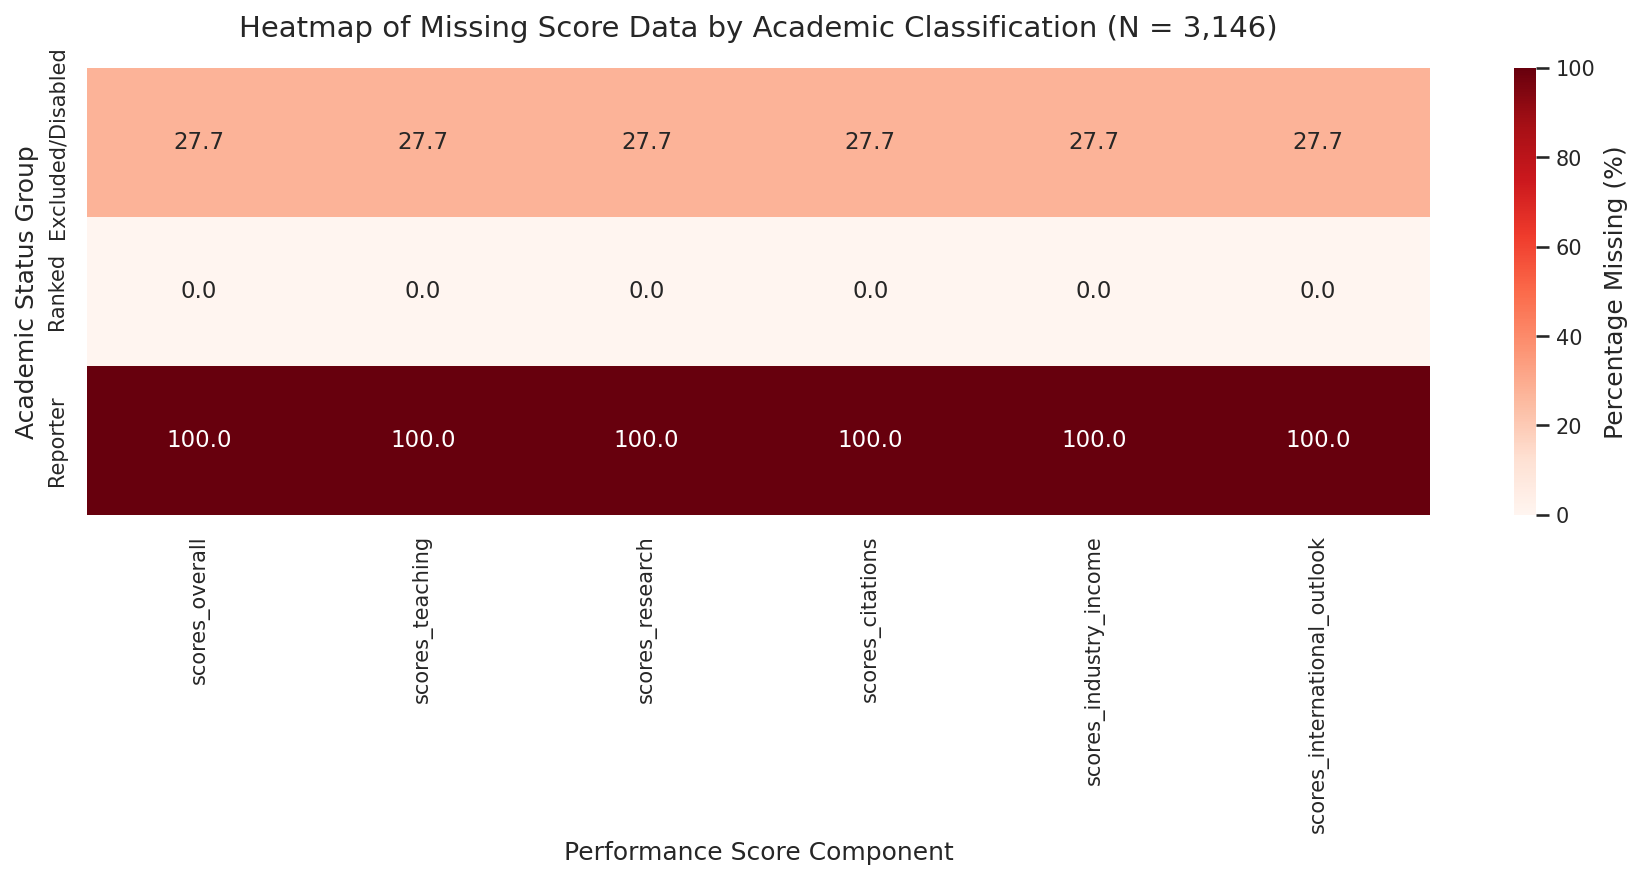

In [31]:
# 6. Missing-data patterns across classifications
# Let's count missing scores across the raw classifications
score_columns_check = [
    'scores_overall', 'scores_teaching', 'scores_research',
    'scores_citations', 'scores_industry_income', 'scores_international_outlook'
]

raw_df = pd.read_csv('times_higher_education_rankings.csv')
raw_df['academic_status'] = df['academic_status']  # Transfer status classification mapping

missing_analysis = raw_df.groupby('academic_status')[score_columns_check].apply(lambda x: x.isna().mean() * 100)

plt.figure(figsize=(12, 6))
sns.heatmap(
    missing_analysis,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    cbar_kws={'label': 'Percentage Missing (%)'}
)
plt.title("Heatmap of Missing Score Data by Academic Classification (N = 3,146)", pad=15)
plt.xlabel("Performance Score Component")
plt.ylabel("Academic Status Group")
plt.tight_layout()
plt.savefig("vis6_missing_data_patterns.png", dpi=300)
plt.show()
plt.close()